<a href="https://colab.research.google.com/github/strangestmahi/statistical-foundation-of-data-science/blob/main/practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

ratings_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/teachingratings.csv"

df = pd.read_csv(ratings_url)

df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1


In [ ]:
print(df.columns)

Index(['minority', 'age', 'gender', 'credits', 'beauty', 'eval', 'division',
       'native', 'tenure', 'students', 'allstudents', 'prof', 'PrimaryLast',
       'vismin', 'female', 'single_credit', 'upper_division',
       'English_speaker', 'tenured_prof'],
      dtype='object')


# T-Test - Does gender affect teaching evaluation rates?

In [ ]:
male_eval = df[df['gender'] == 'male']['eval']
female_eval = df[df['gender'] == 'female']['eval']

t_stat, p_value = stats.ttest_ind(male_eval, female_eval, equal_var=False)
print("Male mean evaluation: ", male_eval.mean())
print("Female mean evaluation: ", female_eval.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Male mean evaluation:  4.06902985163589
Female mean evaluation:  3.901025635156876
T-statistic: 3.2667111105019626
P-value: 0.001176103911892759


In [ ]:
alpha = 0.05
if(p_value < alpha):
  print("Reject null hypothesis")
else:
  print("Fail to reject null hypothesis")

Reject null hypothesis


An independent two-sample t-test was performed to examine whether teaching evaluation scores differ by gender. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. Therefore, there is insufficient statistical evidence to conclude that teaching evaluation scores differ significantly between male and female instructors.

# ANOVA - Does beauty score differ by age?

In [ ]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 30, 40, np.inf],
    labels=['Young', 'Middle', 'Older']
)
df[['age', 'age_group', 'beauty']].head()

,age,age_group,beauty
0,36,Middle,0.289916
1,36,Middle,0.289916
2,36,Middle,0.289916
3,36,Middle,0.289916
4,59,Older,-0.737732


In [ ]:
young = df[df['age_group'] == 'Young']['beauty']
middle = df[df['age_group'] == 'Middle']['beauty']
older = df[df['age_group'] == 'Older']['beauty']

In [ ]:
f_stat, p_stat = stats.f_oneway(young, middle, older)
print("F-statistic:", f_stat)
print("P-value:", p_stat)


F-statistic: 15.655228759236698
P-value: 2.6449618224342487e-07


In [ ]:
alpha = 0.05
if p_value < alpha:
  print("Reject null hypothesis")
else:
  print("Fail to reject null hypothesis")

Reject null hypothesis


A one-way ANOVA was performed to determine whether beauty scores differ significantly across the three age groups. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. Therefore, there is insufficient statistical evidence to conclude that mean beauty scores differ significantly across the age groups.

# Chi-Square - Association between tenure and gender

In [ ]:
contingency_table = pd.crosstab(df['tenure'], df['gender'])
print(contingency_table)

gender  female  male
tenure              
no          50    52
yes        145   216


In [ ]:
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print("Chi-square statistic:", chi2)
print("Degrees of freedom: ", dof)
print("P-value:", p_value)

Chi-square statistic: 2.20678166999886
Degrees of freedom:  1
P-value: 0.1374050603563787


In [ ]:
alpha = 0.05
if p_value < alpha:
  print("Reject null hypothesis")
else:
  print("Fail to reject null hypothesis")

Fail to reject null hypothesis


A chi-square test of independence was conducted to determine whether there is an association between tenure status and gender. Since the p-value is greater than 0.05, we fail to reject the null hypothesis. Therefore, there is insufficient statistical evidence to conclude that tenure status and gender are associated.

# Correlation - Evaluation score vs Beauty score

In [ ]:
correlation, p_value = stats.pearsonr(df['eval'], df['beauty'])
print("Correlation coefficient:", correlation)
print("P-value:", p_value)

Correlation coefficient: 0.18903909084045212
P-value: 4.247115419813557e-05


In [ ]:
if abs(correlation) > 0.3:
  strength = "weak"
elif abs(correlation) < 0.7:
  strength = "moderate"
else:
  strength = "strong"
direction = "positive" if correlation > 0 else "negative"
print(f"The correlation is {strength} and {direction}.")

The correlation is moderate and positive.


In [ ]:
alpha = 0.05
if p_value < alpha:
  print("The correlation is statistically significant")
else:
  print("The correlation is not statistically significant")

The correlation is statistically significant


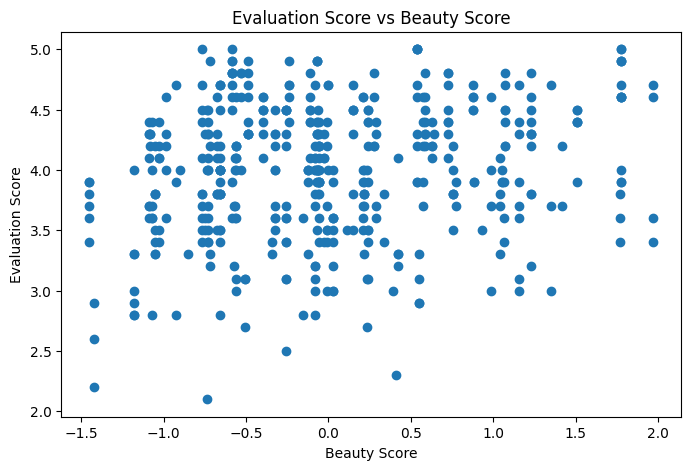

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.scatter(df['beauty'], df['eval'])
plt.xlabel('Beauty Score')
plt.ylabel('Evaluation Score')
plt.title('Evaluation Score vs Beauty Score')
plt.show()

The Pearson correlation analysis shows a positive relationship between beauty score and teaching evaluation score. This indicates that instructors with higher beauty scores tend to have higher teaching evaluation scores. The p-value indicates whether this relationship is statistically significant at the 5% significance level.